In [1]:
import numpy as np
import ot_utils
import comparison_utils
from tqdm import tqdm
import math
import matplotlib.pyplot as plt
from itertools import combinations
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
classification_aucs = np.zeros((8, 8))

for i, j in tqdm(combinations(range(8), 2), total=len(list(combinations(range(8), 2)))):
    self_matrix_1_file = f"../../medium_w2/w2_block_{i}_{i}.npy"
    self_matrix_2_file = f"../../medium_w2/w2_block_{j}_{j}.npy"
    off_diag_matrix_file = f"../../medium_w2/w2_block_{i}_{j}.npy"

    big_matrix = ot_utils.combine_distance_blocks(
        [self_matrix_1_file, off_diag_matrix_file, self_matrix_2_file]
    )

    labels = np.repeat([0, 1], 4000)

    rel_reps = comparison_utils.relative_rep(
        big_matrix, labels, num_classes=2, anchors_per_class=100, seed=42
    )

    y = np.r_[np.zeros(4000, dtype=int), np.ones(4000, dtype=int)]

    X_train, X_test, y_train, y_test = train_test_split(
        rel_reps, y, test_size=0.2, stratify=y, random_state=42
    )

    # SVM with RBF kernel, no scaling
    svc = SVC(kernel="rbf", cache_size=1000)

    # Hyperparameter search
    param_grid = {
        "C": [0.1, 1, 3, 10, 30, 100],
        "gamma": ["scale", 0.001, 0.003, 0.01, 0.03, 0.1],
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    grid = GridSearchCV(
        svc, param_grid=param_grid, scoring="accuracy", cv=cv, n_jobs=-1, verbose=1
    )

    grid.fit(X_train, y_train)

    print("Best params:", grid.best_params_)
    # print("CV best score (mean acc):", grid.best_score_)

    # Evaluate on held-out test set
    best_model = grid.best_estimator_
    y_pred = best_model.predict(X_test)

    # print("\nTest set report:")
    # print(classification_report(y_test, y_pred, digits=4))
    # print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

    # If you want ROC-AUC
    y_score = best_model.decision_function(X_test)
    classification_aucs[i, j] = roc_auc_score(y_test, y_score)
    print("Test ROC-AUC:", classification_aucs[i, j])

classification_aucs = classification_aucs + classification_aucs.T

  0%|          | 0/28 [00:00<?, ?it/s]

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best params: {'C': 100, 'gamma': 'scale'}


  4%|▎         | 1/28 [01:10<31:46, 70.62s/it]

Test ROC-AUC: 0.9898578125
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best params: {'C': 100, 'gamma': 'scale'}


  7%|▋         | 2/28 [02:14<28:45, 66.37s/it]

...

Test ROC-AUC: 0.6268265625
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best params: {'C': 30, 'gamma': 'scale'}


 96%|█████████▋| 27/28 [1:10:05<02:36, 156.15s/it]

Test ROC-AUC: 0.9769531249999999
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best params: {'C': 30, 'gamma': 'scale'}


100%|██████████| 28/28 [1:11:20<00:00, 152.86s/it]

Test ROC-AUC: 0.96609375


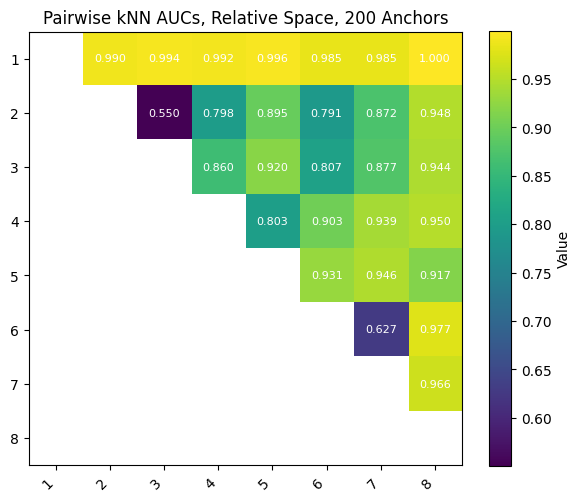

In [ ]:
A = classification_aucs.copy()
n = A.shape[0]

# mask: keep only strict upper triangle (k=1), hide everything else
mask = np.triu(np.ones_like(A, dtype=bool), k=1)
plot_A = np.where(mask, A, np.nan)

# color range: min non-zero to max over the visible (unmasked) cells
vals = plot_A[~np.isnan(plot_A)]
nonzero = vals[vals != 0]
vmin, vmax = float(nonzero.min()), float(nonzero.max())

fig, ax = plt.subplots(figsize=(6, 5))
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad(color=(1, 1, 1, 0))  # transparent for masked cells

im = ax.imshow(plot_A, cmap=cmap, vmin=vmin, vmax=vmax)

# axes and labels
ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels([f"{i + 1}" for i in range(n)], rotation=45, ha="right")
ax.set_yticklabels([f"{i + 1}" for i in range(n)])
ax.set_title("Pairwise kNN AUCs, Relative Space, 200 Anchors")

# colorbar (uses the vmin/vmax above, so no zeros)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Value")

# annotate only the strict upper triangle
for i in range(n):
    for j in range(i + 1, n):
        ax.text(
            j, i, f"{A[i, j]:.3f}", ha="center", va="center", fontsize=8, color="black"
        )

plt.tight_layout()
plt.show()

In [ ]:
classification_aucs = np.zeros((8, 8))

for i, j in tqdm(combinations(range(8), 2), total=len(list(combinations(range(8), 2)))):
    self_matrix_1_file = f"../../medium_w2/w2_block_{i}_{i}.npy"
    self_matrix_2_file = f"../../medium_w2/w2_block_{j}_{j}.npy"
    off_diag_matrix_file = f"../../medium_w2/w2_block_{i}_{j}.npy"

    big_matrix = ot_utils.combine_distance_blocks(
        [self_matrix_1_file, off_diag_matrix_file, self_matrix_2_file]
    )

    labels = np.repeat([0, 1], 4000)

    rel_reps = comparison_utils.relative_rep(
        big_matrix, labels, num_classes=2, anchors_per_class=10, seed=42
    )

    y = np.r_[np.zeros(4000, dtype=int), np.ones(4000, dtype=int)]

    X_train, X_test, y_train, y_test = train_test_split(
        rel_reps, y, test_size=0.2, stratify=y, random_state=42
    )

    # SVM with RBF kernel, no scaling
    svc = SVC(kernel="rbf", cache_size=1000)

    # Hyperparameter search
    param_grid = {
        "C": [0.1, 1, 3, 10, 30, 100],
        "gamma": ["scale", 0.001, 0.003, 0.01, 0.03, 0.1],
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    grid = GridSearchCV(
        svc, param_grid=param_grid, scoring="accuracy", cv=cv, n_jobs=-1, verbose=1
    )

    grid.fit(X_train, y_train)

    print("Best params:", grid.best_params_)
    print("CV best score (mean acc):", grid.best_score_)

    # Evaluate on held-out test set
    best_model = grid.best_estimator_
    y_pred = best_model.predict(X_test)

    # print("\nTest set report:")
    # print(classification_report(y_test, y_pred, digits=4))
    # print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

    # If you want ROC-AUC
    y_score = best_model.decision_function(X_test)
    classification_aucs[i, j] = roc_auc_score(y_test, y_score)
    print("Test ROC-AUC:", classification_aucs[i, j])

classification_aucs = classification_aucs + classification_aucs.T

  0%|          | 0/28 [00:00<?, ?it/s]

Fitting 5 folds for each of 36 candidates, totalling 180 fits


  4%|▎         | 1/28 [00:07<03:34,  7.96s/it]

Best params: {'C': 100, 'gamma': 'scale'}
CV best score (mean acc): 0.9490624999999999
Test ROC-AUC: 0.9896843750000001
Fitting 5 folds for each of 36 candidates, totalling 180 fits


  7%|▋         | 2/28 [00:15<03:21,  7.73s/it]

...

Test ROC-AUC: 0.6128203125
Fitting 5 folds for each of 36 candidates, totalling 180 fits


 96%|█████████▋| 27/28 [06:31<00:14, 14.55s/it]

Best params: {'C': 30, 'gamma': 'scale'}
CV best score (mean acc): 0.94078125
Test ROC-AUC: 0.9754546875
Fitting 5 folds for each of 36 candidates, totalling 180 fits


100%|██████████| 28/28 [06:39<00:00, 14.28s/it]

Best params: {'C': 30, 'gamma': 'scale'}
CV best score (mean acc): 0.94859375
Test ROC-AUC: 0.9639484374999999


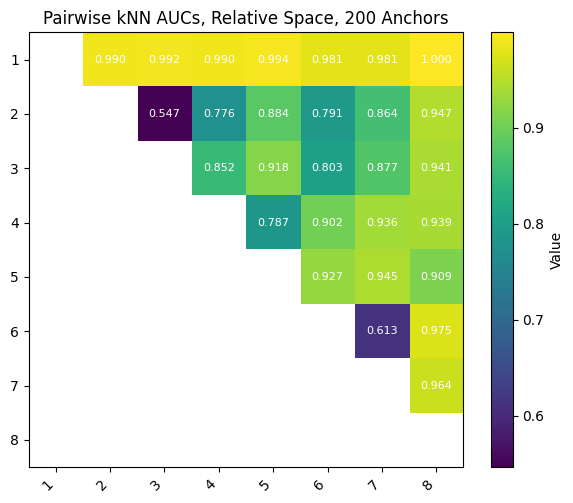

In [ ]:
A = classification_aucs.copy()
n = A.shape[0]

# mask: keep only strict upper triangle (k=1), hide everything else
mask = np.triu(np.ones_like(A, dtype=bool), k=1)
plot_A = np.where(mask, A, np.nan)

# color range: min non-zero to max over the visible (unmasked) cells
vals = plot_A[~np.isnan(plot_A)]
nonzero = vals[vals != 0]
vmin, vmax = float(nonzero.min()), float(nonzero.max())

fig, ax = plt.subplots(figsize=(6, 5))
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad(color=(1, 1, 1, 0))  # transparent for masked cells

im = ax.imshow(plot_A, cmap=cmap, vmin=vmin, vmax=vmax)

# axes and labels
ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels([f"{i + 1}" for i in range(n)], rotation=45, ha="right")
ax.set_yticklabels([f"{i + 1}" for i in range(n)])
ax.set_title("Pairwise kNN AUCs, Relative Space, 200 Anchors")

# colorbar (uses the vmin/vmax above, so no zeros)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Value")

# annotate only the strict upper triangle
for i in range(n):
    for j in range(i + 1, n):
        ax.text(
            j, i, f"{A[i, j]:.3f}", ha="center", va="center", fontsize=8, color="black"
        )

plt.tight_layout()
plt.show()

In [11]:
classification_aucs = np.zeros((8, 8))

for i, j in tqdm(combinations(range(8), 2), total=len(list(combinations(range(8), 2)))):
    self_matrix_1_file = f"../../medium_w2/w2_block_{i}_{i}.npy"
    self_matrix_2_file = f"../../medium_w2/w2_block_{j}_{j}.npy"
    off_diag_matrix_file = f"../../medium_w2/w2_block_{i}_{j}.npy"

    big_matrix = ot_utils.combine_distance_blocks(
        [self_matrix_1_file, off_diag_matrix_file, self_matrix_2_file]
    )

    labels = np.repeat([0, 1], 4000)

    rel_reps = comparison_utils.relative_rep(
        big_matrix, labels, num_classes=2, anchors_per_class=1, seed=42
    )

    y = np.r_[np.zeros(4000, dtype=int), np.ones(4000, dtype=int)]

    X_train, X_test, y_train, y_test = train_test_split(
        rel_reps, y, test_size=0.2, stratify=y, random_state=42
    )

    # SVM with RBF kernel, no scaling
    svc = SVC(kernel="rbf", cache_size=1000)

    # Hyperparameter search
    param_grid = {
        "C": [0.1, 1, 3, 10, 30, 100],
        "gamma": ["scale", 0.001, 0.003, 0.01, 0.03, 0.1],
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    grid = GridSearchCV(
        svc, param_grid=param_grid, scoring="accuracy", cv=cv, n_jobs=-1, verbose=1
    )

    grid.fit(X_train, y_train)

    print("Best params:", grid.best_params_)
    print("CV best score (mean acc):", grid.best_score_)

    # Evaluate on held-out test set
    best_model = grid.best_estimator_
    y_pred = best_model.predict(X_test)

    # print("\nTest set report:")
    # print(classification_report(y_test, y_pred, digits=4))
    # print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

    # If you want ROC-AUC
    y_score = best_model.decision_function(X_test)
    classification_aucs[i, j] = roc_auc_score(y_test, y_score)
    print("Test ROC-AUC:", classification_aucs[i, j])

classification_aucs = classification_aucs + classification_aucs.T

  0%|          | 0/28 [00:00<?, ?it/s]

Fitting 5 folds for each of 36 candidates, totalling 180 fits


  4%|▎         | 1/28 [00:08<03:58,  8.84s/it]

Best params: {'C': 10, 'gamma': 'scale'}
CV best score (mean acc): 0.9256249999999999
Test ROC-AUC: 0.9644562499999999
Fitting 5 folds for each of 36 candidates, totalling 180 fits


  7%|▋         | 2/28 [00:17<03:40,  8.47s/it]

...

Test ROC-AUC: 0.5633625
Fitting 5 folds for each of 36 candidates, totalling 180 fits


 96%|█████████▋| 27/28 [04:42<00:10, 10.28s/it]

Best params: {'C': 100, 'gamma': 'scale'}
CV best score (mean acc): 0.8295312500000002
Test ROC-AUC: 0.884559375
Fitting 5 folds for each of 36 candidates, totalling 180 fits


100%|██████████| 28/28 [04:50<00:00, 10.36s/it]

Best params: {'C': 100, 'gamma': 'scale'}
CV best score (mean acc): 0.900625
Test ROC-AUC: 0.9197265625


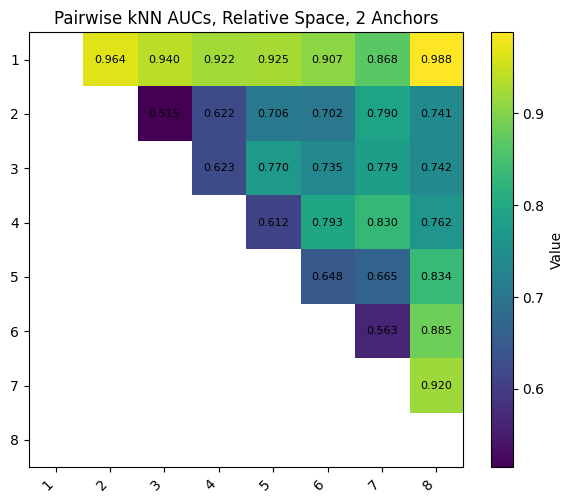

In [13]:
A = classification_aucs.copy()
n = A.shape[0]

# mask: keep only strict upper triangle (k=1), hide everything else
mask = np.triu(np.ones_like(A, dtype=bool), k=1)
plot_A = np.where(mask, A, np.nan)

# color range: min non-zero to max over the visible (unmasked) cells
vals = plot_A[~np.isnan(plot_A)]
nonzero = vals[vals != 0]
vmin, vmax = float(nonzero.min()), float(nonzero.max())

fig, ax = plt.subplots(figsize=(6, 5))
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad(color=(1, 1, 1, 0))  # transparent for masked cells

im = ax.imshow(plot_A, cmap=cmap, vmin=vmin, vmax=vmax)

# axes and labels
ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels([f"{i + 1}" for i in range(n)], rotation=45, ha="right")
ax.set_yticklabels([f"{i + 1}" for i in range(n)])
ax.set_title("Pairwise kNN AUCs, Relative Space, 2 Anchors")

# colorbar (uses the vmin/vmax above, so no zeros)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Value")

# annotate only the strict upper triangle
for i in range(n):
    for j in range(i + 1, n):
        ax.text(
            j, i, f"{A[i, j]:.3f}", ha="center", va="center", fontsize=8, color="black"
        )

plt.tight_layout()
plt.show()

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best params: {'C': 100, 'gamma': 'scale'}
CV best score (mean acc): 0.79859375
0.8679937500000001


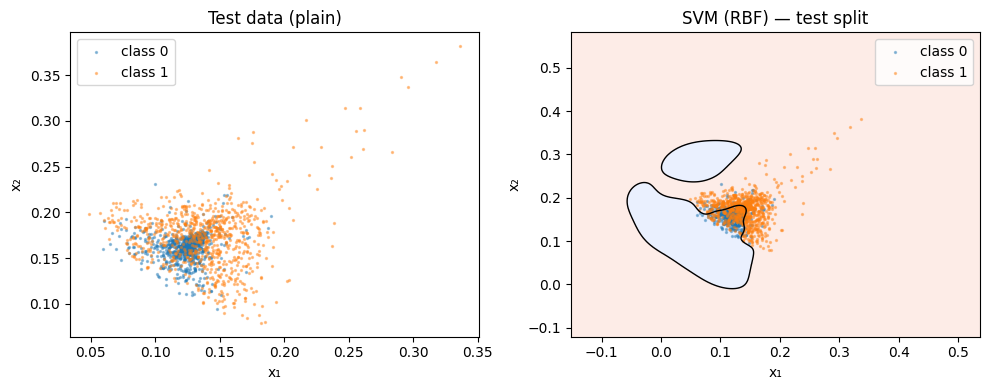

In [30]:
i = 0
j = 6
self_matrix_1_file = f"../../medium_w2/w2_block_{i}_{i}.npy"
self_matrix_2_file = f"../../medium_w2/w2_block_{j}_{j}.npy"
off_diag_matrix_file = f"../../medium_w2/w2_block_{i}_{j}.npy"

big_matrix = ot_utils.combine_distance_blocks(
    [self_matrix_1_file, off_diag_matrix_file, self_matrix_2_file]
)

labels = np.repeat([0, 1], 4000)

rel_reps = comparison_utils.relative_rep(
    big_matrix, labels, num_classes=2, anchors_per_class=1, seed=42
)

y = np.r_[np.zeros(4000, dtype=int), np.ones(4000, dtype=int)]

X_train, X_test, y_train, y_test = train_test_split(
    rel_reps, y, test_size=0.2, stratify=y, random_state=42
)

# SVM with RBF kernel, no scaling
svc = SVC(kernel="rbf", cache_size=1000)

# Hyperparameter search
param_grid = {
    "C": [0.1, 1, 3, 10, 30, 100],
    "gamma": ["scale", 0.001, 0.003, 0.01, 0.03, 0.1],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    svc, param_grid=param_grid, scoring="accuracy", cv=cv, n_jobs=-1, verbose=1
)

grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("CV best score (mean acc):", grid.best_score_)

# Evaluate on held-out test set
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

# print("\nTest set report:")
# print(classification_report(y_test, y_pred, digits=4))
# print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

# If you want ROC-AUC
y_score = best_model.decision_function(X_test)
print(roc_auc_score(y_test, y_score))


def plot_svm_side_by_side_clean(
    clf,
    X_test,
    y_test,
    X_train=None,
    y_train=None,  # optional: to show training SVs properly
    title="SVM (RBF) — decision boundary",
    pad=0.2,
    steps=300,
    show_train_sv=True,
):
    X_test = np.asarray(X_test)
    y_test = np.asarray(y_test)

    # Grid over test bounds
    xmin, xmax = X_test[:, 0].min() - pad, X_test[:, 0].max() + pad
    ymin, ymax = X_test[:, 1].min() - pad, X_test[:, 1].max() + pad
    xx, yy = np.meshgrid(np.linspace(xmin, xmax, steps), np.linspace(ymin, ymax, steps))
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = clf.decision_function(grid).reshape(xx.shape)

    # Layout: 2 panels by default; 3rd panel if train is given
    ncols = 3 if (X_train is not None and y_train is not None and show_train_sv) else 2
    fig, axes = plt.subplots(1, ncols, figsize=(5 * ncols, 4), squeeze=False)
    ax0, ax1 = axes[0, 0], axes[0, 1]

    # --- Left: plain test distribution ---
    ax0.scatter(
        X_test[y_test == y_test.min(), 0],
        X_test[y_test == y_test.min(), 1],
        s=2,
        alpha=0.4,
        label=f"class {int(y_test.min())}",
    )
    ax0.scatter(
        X_test[y_test == y_test.max(), 0],
        X_test[y_test == y_test.max(), 1],
        s=2,
        alpha=0.4,
        label=f"class {int(y_test.max())}",
    )
    ax0.set_title("Test data (plain)")
    ax0.set_xlabel("x₁")
    ax0.set_ylabel("x₂")
    ax0.legend()

    # --- Right: decision boundary over test region (no SVs here) ---
    ax1.contourf(xx, yy, zz > 0, alpha=0.18, cmap="coolwarm")
    ax1.contour(xx, yy, zz, levels=[0], colors="k", linewidths=1)
    ax1.scatter(
        X_test[y_test == y_test.min(), 0],
        X_test[y_test == y_test.min(), 1],
        s=2,
        alpha=0.4,
        label=f"class {int(y_test.min())}",
    )
    ax1.scatter(
        X_test[y_test == y_test.max(), 0],
        X_test[y_test == y_test.max(), 1],
        s=2,
        alpha=0.4,
        label=f"class {int(y_test.max())}",
    )
    ax1.set_title(title)
    ax1.set_xlabel("x₁")
    ax1.set_ylabel("x₂")
    ax1.legend()

    # --- Optional 3rd panel: training data with support vectors ---
    if ncols == 3:
        X_train = np.asarray(X_train)
        y_train = np.asarray(y_train)
        ax2 = axes[0, 2]
        ax2.scatter(
            X_train[y_train == y_train.min(), 0],
            X_train[y_train == y_train.min(), 1],
            s=2,
            alpha=0.6,
            label=f"class {int(y_train.min())}",
        )
        ax2.scatter(
            X_train[y_train == y_train.max(), 0],
            X_train[y_train == y_train.max(), 1],
            s=2,
            alpha=0.6,
            label=f"class {int(y_train.max())}",
        )
        # Support vectors live in the training set
        try:
            sv = clf.support_vectors_
        except AttributeError:
            # pipeline case
            svc = clf.named_steps["svc"]
            sv = svc.support_vectors_
            scaler = clf.named_steps.get("standardscaler", None)
            if scaler is not None:
                sv = scaler.inverse_transform(sv)
        ax2.scatter(
            sv[:, 0],
            sv[:, 1],
            s=50,
            facecolors="none",
            edgecolors="k",
            linewidths=1.2,
            label="support vectors",
        )
        ax2.set_title("Train data (SVs shown)")
        ax2.set_xlabel("x₁")
        ax2.set_ylabel("x₂")
        ax2.legend()

    plt.tight_layout()
    plt.show()


plot_svm_side_by_side_clean(
    best_model, X_test, y_test, title="SVM (RBF) — test split"
)

In [18]:
print(y_test.shape)

(1600,)


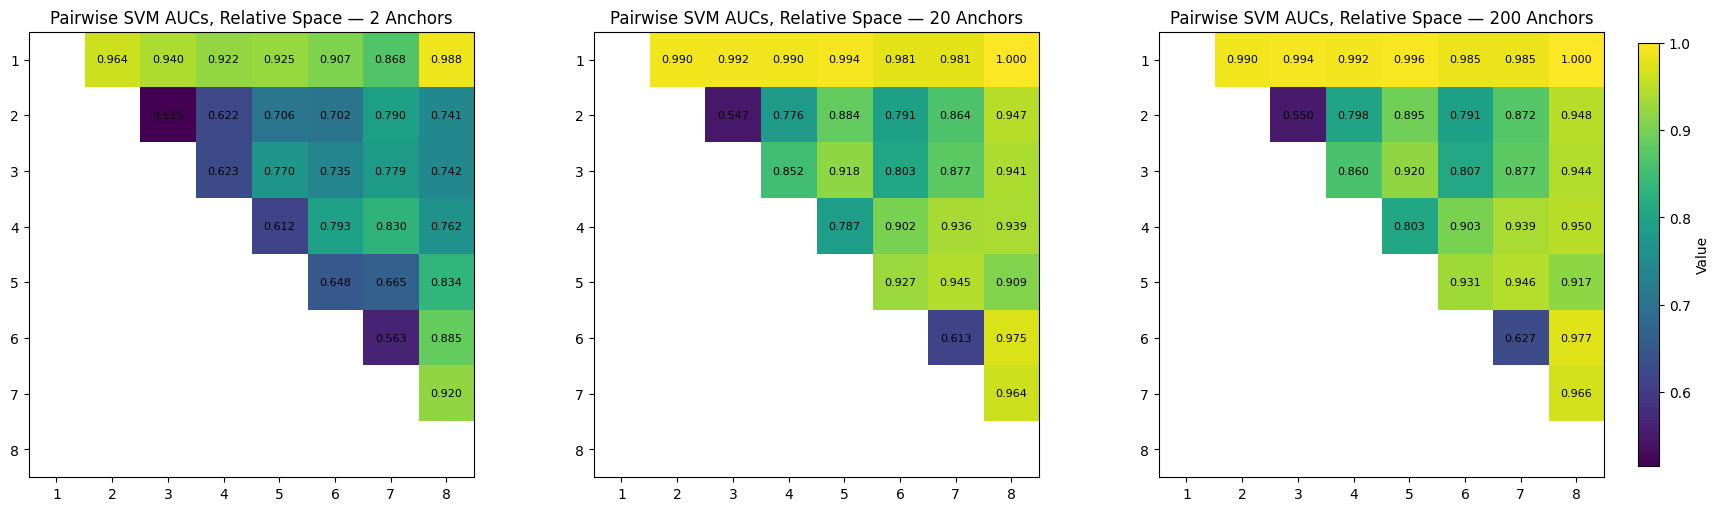

In [27]:
A3 = np.array(
    [
        [0.000, 0.990, 0.994, 0.992, 0.996, 0.985, 0.985, 1.000],
        [0.990, 0.000, 0.550, 0.798, 0.895, 0.791, 0.872, 0.948],
        [0.994, 0.550, 0.000, 0.860, 0.920, 0.807, 0.877, 0.944],
        [0.992, 0.798, 0.860, 0.000, 0.803, 0.903, 0.939, 0.950],
        [0.996, 0.895, 0.920, 0.803, 0.000, 0.931, 0.946, 0.917],
        [0.985, 0.791, 0.807, 0.903, 0.931, 0.000, 0.627, 0.977],
        [0.985, 0.872, 0.877, 0.939, 0.946, 0.627, 0.000, 0.966],
        [1.000, 0.948, 0.944, 0.950, 0.917, 0.977, 0.966, 0.000],
    ]
)

A2 = np.array(
    [
        [0.000, 0.990, 0.992, 0.990, 0.994, 0.981, 0.981, 1.000],
        [0.990, 0.000, 0.547, 0.776, 0.884, 0.791, 0.864, 0.947],
        [0.992, 0.547, 0.000, 0.852, 0.918, 0.803, 0.877, 0.941],
        [0.990, 0.776, 0.852, 0.000, 0.787, 0.902, 0.936, 0.939],
        [0.994, 0.884, 0.918, 0.787, 0.000, 0.927, 0.945, 0.909],
        [0.981, 0.791, 0.803, 0.902, 0.927, 0.000, 0.613, 0.975],
        [0.981, 0.864, 0.877, 0.936, 0.945, 0.613, 0.000, 0.964],
        [1.000, 0.947, 0.941, 0.939, 0.909, 0.975, 0.964, 0.000],
    ]
)

A1 = np.array(
    [
        [0.000, 0.964, 0.940, 0.922, 0.925, 0.907, 0.868, 0.988],
        [0.964, 0.000, 0.515, 0.622, 0.706, 0.702, 0.790, 0.741],
        [0.940, 0.515, 0.000, 0.623, 0.770, 0.735, 0.779, 0.742],
        [0.922, 0.622, 0.623, 0.000, 0.612, 0.793, 0.830, 0.762],
        [0.925, 0.706, 0.770, 0.612, 0.000, 0.648, 0.665, 0.834],
        [0.907, 0.702, 0.735, 0.793, 0.648, 0.000, 0.563, 0.885],
        [0.868, 0.790, 0.779, 0.830, 0.665, 0.563, 0.000, 0.920],
        [0.988, 0.741, 0.742, 0.762, 0.834, 0.885, 0.920, 0.000],
    ]
)

mats = [A1, A2, A3]
titles = ["2 Anchors", "20 Anchors", "200 Anchors"]

# Optional: enforce symmetry
mats = [np.maximum(M, M.T) for M in mats]

n = mats[0].shape[0]
mask = np.tri(n, k=0, dtype=bool)  # hide diagonal + lower triangle

# >>> shared color scale from UPPER TRIANGLE ONLY (exclude diagonal)
ut_r, ut_c = np.triu_indices(n, k=1)
vmin = min(np.nanmin(M[ut_r, ut_c]) for M in mats)
vmax = max(np.nanmax(M[ut_r, ut_c]) for M in mats)
# <<<

fig, axs = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)

cmap = plt.get_cmap().copy()
cmap.set_bad(alpha=0.0)

ims = []
for ax, M, t in zip(axs, mats, titles):
    MM = np.ma.array(M, mask=mask)
    im = ax.imshow(MM, vmin=vmin, vmax=vmax, cmap=cmap)
    ims.append(im)

    ax.set_title(f"Pairwise SVM AUCs, Relative Space — {t}")
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(range(1, n + 1))
    ax.set_yticklabels(range(1, n + 1))
    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)

    for i in range(n):
        for j in range(i + 1, n):
            ax.text(j, i, f"{M[i, j]:.3f}", ha="center", va="center", fontsize=8)

cbar = fig.colorbar(ims[0], ax=axs, pad=0.02, shrink=0.95)
cbar.set_label("Value")
plt.show()